# Tutorial 4: Mouse brain (P22, spatial CUT&Tag–RNA-seq, H3K27ac)

Identify spatial domains from H3K27ac profiles in a P22 mouse brain section and visualize their organization. This example uses H3K27ac CUT&Tag counts, spatial coordinates and peak–motif associations. Co-profiled RNA is not used in this analysis.

**Original study.** [Zhang et al., Nature (2023)](https://doi.org/10.1038/s41586-023-05795-1); [GEO GSE205055](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE205055).

**Output provenance.** Saved outputs document the completed example run; environment labels and paths describe that recorded execution.


## 1. Environment and configuration

Open the notebook in the pinned Python 3.10 environment described in the [installation guide](../docs/installation.rst). See [input data](../docs/data_access.rst) for the example files.

The selected profile is `tutorials/configs/P22_H3K27ac.json`. Its example defaults use 9,370 spots, 500 training epochs, 30 shards and a target of 11 spatial domains. The default count and motif files are in `data/P22_H3K27ac/`; provided mode selects the saved `result/P22_H3K27ac/training/embeddings/500_epoch/` exports. New executions write under `OUTPUT_DIR`, which defaults to `result/P22_H3K27ac/`.

Edit `ATAC_PATH`, optional `MOTIF_PATH`, `OUTPUT_DIR` and `TARGET_K` for your data. Here, `ATAC_PATH` is the shared count-input variable for the H3K27ac CUT&Tag matrix. `DATASET` labels the run; `CONFIG_PATH` independently selects its defaults. The filtering, network, training, analysis and execution dictionaries expose the settings used below. `MOTIF_OPTIONS` selects existing annotations, sequence scanning, or a model without motif nodes.

`RUN_MODE="train"` prepares inputs and trains a new model. Set `RUN_MODE="provided"` and choose `EMBEDDING_DIR` to analyze existing exports; this skips training preparation and training but fits new domains and UMAPs. Rerun the cells in order after changing the configuration.

For CUDA training, `SEAREG_PHYSICAL_GPU` selects the physical card; the profile default is 0. For CPU training, set `TRAINING_OPTIONS["device"]="cpu"` and `EXECUTION_OPTIONS["physical_gpu"]=None`, with `SEAREG_PHYSICAL_GPU` unset. Provided mode needs no GPU or training job.


In [1]:
from pathlib import Path
from dataclasses import asdict
import hashlib
import json
import os
import sys
import time
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "seareg" / "__init__.py").is_file() and (p / "tutorials").is_dir())
sys.path.insert(0, str(ROOT))
import seareg as sr
sys.path.insert(0, str(ROOT / "tutorials"))
from seareg_tutorial_data import prepare_input_file, create_run_directory
from seareg_tutorial_embeddings import load_tutorial_embeddings

# One input interface: the bundled paths and settings below are editable defaults.
# Keep the profile independent of the run label; a new DATASET needs no new profile.
CONFIG_PATH = ROOT / "tutorials" / "configs" / "P22_H3K27ac.json"
profile = json.loads(CONFIG_PATH.read_text())
DATASET = "P22_H3K27ac"  # A label for this run.
RUN_MODE = "train"  # "train" or "provided"; rerun from this cell after changing inputs.
ATAC_PATH = (CONFIG_PATH.parent / profile["input"]["atac"]).resolve()
MOTIF_PATH = ((CONFIG_PATH.parent / profile["input"]["dna"]).resolve()
              if profile["input"].get("dna") else None)
EMBEDDING_DIR = ROOT / "result" / "P22_H3K27ac" / "training" / "embeddings" / "500_epoch"
OUTPUT_DIR = ROOT / "result" / DATASET  # May be any writable directory.
TARGET_K = profile["analysis"]["target_domains"][0]

# Set enabled=False for counts-only training. With source="auto", a missing
# motif matrix uses the Workflow's R scanner after filtering. Select the actual
# assembly (or counts metadata) and species; fasta may name a local reference.
MOTIF_OPTIONS = {
    "enabled": True,
    "source": "auto",  # "auto", "read", or "scan".
    "genome": os.environ.get("SEAREG_REFERENCE_ASSEMBLY", "").strip() or None,
    "fasta": os.environ.get("SEAREG_REFERENCE_FASTA", "").strip() or None,
    "species_names": [name.strip() for name in os.environ.get(
        "SEAREG_MOTIF_SPECIES", "Homo sapiens,Mus musculus").split(",") if name.strip()],
    "rscript": os.environ.get("SEAREG_RSCRIPT", "Rscript"),
    "threads": 1,
    "auto_build_dna": True,
    "download_reference": True,
}
# Override individual values here, keeping each example's original defaults.
FILTERING_OPTIONS = {**profile["filtering"]}
NETWORK_OPTIONS = {**profile["network"]}
TRAINING_OPTIONS = {**profile["training"]}
ANALYSIS_OPTIONS = {**profile["analysis"]}
EXECUTION_OPTIONS = {**(profile["execution"] if RUN_MODE == "train" else {
    "physical_gpu": None, "torch_threads": 1, "torch_interop_threads": 1,
    "blas_threads": 1, "strict_algorithms": True, "tf32": False,
})}

if RUN_MODE not in {"provided", "train"}:
    raise ValueError("RUN_MODE must be provided or train")
training_config = sr.TrainConfig(**TRAINING_OPTIONS)
analysis_config = sr.AnalysisConfig(**{**ANALYSIS_OPTIONS, "target_domains": (TARGET_K,)})
execution = dict(EXECUTION_OPTIONS)
if RUN_MODE == "train" and "SEAREG_PHYSICAL_GPU" in os.environ:
    execution["physical_gpu"] = int(os.environ["SEAREG_PHYSICAL_GPU"])
print("SEAREG:", sr.__version__)
print("Dataset / mode:", DATASET, RUN_MODE)
if RUN_MODE == "train":
    print("Training device / physical GPU:", training_config.device, execution["physical_gpu"])
    print("Epochs / shards:", training_config.epochs, training_config.shards)
else:
    print("Using the selected embeddings; no model training or GPU is required.")


SEAREG: 0.5.0.dev3
Dataset / device / physical GPU: P22_H3K27ac cuda:0 2
Epochs / shards: 500 30
Loss backend / strict / TF32: auto False False


## 2. Prepare inputs and reserve a new run

Locate the selected count matrix and optional motif resource, extract bundled compressed inputs when needed, and create a separate directory for this execution. In training mode, configure the workflow used by the following preparation steps. In provided mode, check the selected embedding exports against the count-matrix spot and peak identities before analysis.

Motif import or scanning takes place after peak filtering in step 5.


In [2]:
def file_sha256(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            hasher.update(block)
    return hasher.hexdigest()

def display_path(path):
    path = Path(path).expanduser().resolve()
    return str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path)

# Existing selected files are accepted directly. Only a missing exact bundled
# path can use checked archive extraction; custom paths never select an example.
ATAC_PATH = prepare_input_file(ATAC_PATH, bundle_root=ROOT)
input_hashes = {display_path(ATAC_PATH): file_sha256(ATAC_PATH)}
OUTPUT_DIR = Path(OUTPUT_DIR).expanduser().resolve()
provided_embeddings = None
if RUN_MODE == "provided":
    EMBEDDING_DIR = Path(EMBEDDING_DIR).expanduser().resolve()
    provided_embeddings = load_tutorial_embeddings(EMBEDDING_DIR, counts_path=ATAC_PATH)
elif MOTIF_OPTIONS["enabled"] and MOTIF_PATH is not None and MOTIF_OPTIONS["source"] != "scan":
    MOTIF_PATH = Path(MOTIF_PATH).expanduser().resolve()
    # Transport only: matrix import and scanning occur in step 5, after filtering.
    prepare_input_file(MOTIF_PATH, bundle_root=ROOT, required=False)

# Check chosen counts (and provided exports) before reserving any output.
RUN_DIR = create_run_directory(ROOT, DATASET, RUN_MODE, output=OUTPUT_DIR)
stage_seconds = {}
notebook_started = time.perf_counter()
flow = None
if RUN_MODE == "train":
    inputs = {"atac": str(ATAC_PATH)}
    if MOTIF_OPTIONS["enabled"] and MOTIF_PATH is not None:
        inputs["dna"] = str(Path(MOTIF_PATH).expanduser().resolve())
    motif_options = {key: value for key, value in MOTIF_OPTIONS.items() if value is not None}
    if motif_options.get("fasta"):
        motif_options["fasta"] = str(Path(motif_options["fasta"]).expanduser().resolve())
    if "/" in str(motif_options.get("rscript", "")):
        motif_options["rscript"] = str(Path(motif_options["rscript"]).expanduser().resolve())
    run_profile = {**profile, "schema_version": 2, "dataset_id": DATASET,
                   "input": inputs, "motif": motif_options, "output": str(RUN_DIR),
                   "filtering": FILTERING_OPTIONS, "network": NETWORK_OPTIONS,
                   "training": TRAINING_OPTIONS,
                   "analysis": {**ANALYSIS_OPTIONS, "target_domains": [TARGET_K]},
                   "execution": execution}
    flow = sr.Workflow(run_profile)
    # Capture the actual matrix selected by Workflow, including local auto-discovery.
    selected_motif_path = flow.config["input"].get("dna")
    if selected_motif_path is not None:
        input_hashes[display_path(selected_motif_path)] = file_sha256(selected_motif_path)
print("Run:", display_path(RUN_DIR))
print("Input SHA-256:", input_hashes)


Fresh run: results/P22_H3K27ac/github_fresh_20261019T181535Z
Verified input SHA-256: {'data/P22_H3K27ac/counts.h5ad': '9f957b5ef1df8e9936e4ea1596c05a20c351ffc6a0346f7ec8e215ba9883eeec', 'data/P22_H3K27ac/motifs.h5': '66040e614cb4b7e4a3bded867226da39624ce487b29448d9e6304e92b48f98d3'}


## 3. Inspect counts and spatial coordinates

Preview a backed matrix slice: rows are spots and columns are genomic peaks. Read spatial coordinates in their native XY orientation.


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

adata = ad.read_h5ad(ATAC_PATH, backed="r")
try:
    print(adata)
    # Select sparse major-axis vectors without materializing the full matrix.
    matrix = adata.X
    if getattr(matrix, "format", None) == "csr":
        block = matrix[np.arange(adata.n_obs) < 5, :5]
    elif getattr(matrix, "format", None) == "csc":
        block = matrix[:5, np.arange(adata.n_vars) < 5]
    else:
        block = matrix[:5, :5]
    values = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
    display(pd.DataFrame(values, index=adata.obs_names[:5], columns=adata.var_names[:5]))
    display(pd.DataFrame(np.asarray(adata.obsm["spatial"])[:5, :2],
                         index=adata.obs_names[:5], columns=["x", "y"]))
finally:
    adata.file.close()
del adata, matrix, block, values


AnnData object with n_obs × n_vars = 9370 × 87043 backed at '/home/disk1/xiemingyu/download/SEAREG/data/P22_H3K27ac/counts.h5ad'
    obsm: 'spatial'


,GL456216.1-15618-17428,GL456216.1-31350-33064,GL456216.1-33432-34461,GL456233.1-38838-39324,GL456233.1-110916-111494
AAACATCGAGAGTCAA-1,0,0,0,0,0
AAACATCGAGATCGCA-1,0,0,0,0,0
AAACATCGAGCAGGAA-1,0,0,0,0,0
AAACATCGAGTCACTA-1,0,0,1,0,0
AAACATCGATCCTGTA-1,0,0,0,0,0


,x,y
AAACATCGAGAGTCAA-1,-641,-2709
AAACATCGAGATCGCA-1,-669,-2709
AAACATCGAGCAGGAA-1,-696,-2709
AAACATCGAGTCACTA-1,-724,-2709
AAACATCGATCCTGTA-1,-751,-2709


## 4. Filter the count matrix

Apply chromosome and across-spot peak-detection filters. Preserve all spots and the raw counts for retained peaks, and save the filtered matrix, peak IDs and filtering report for the subsequent motif and network steps. This preparation step runs only in training mode.


In [4]:
if RUN_MODE == "train":
    started = time.perf_counter()
    filtered = flow.filter()
    stage_seconds["filter_counts"] = time.perf_counter() - started
    if filtered.metadata["source"]["sha256"] != input_hashes[display_path(ATAC_PATH)]:
        raise ValueError("Counts changed between validation and filtering")
    print("Filtered shape:", filtered.metadata["shape"])
    print("Retained peaks:", len(filtered.peak_ids))
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


Filtered shape: (9370, 84998)
Retained peaks: 84998


## 5. Prepare peak–motif annotations

Import the selected peak–motif matrix or scan the retained peak sequences with `flow.prepare_motif()`. These associations supply the peak–motif links used by the model. Set `MOTIF_OPTIONS["enabled"]=False` for a model without motif nodes.

For scanning, select the reference assembly and motif species in the configuration cell; a matching local FASTA is optional. See [motif annotation](../docs/motif_annotation.rst) for R setup and scanner options. Provided mode uses the selected embedding exports and skips motif preparation.


In [5]:
if RUN_MODE == "train":
    started = time.perf_counter()
    selected_motif = flow.prepare_motif()
    stage_seconds["prepare_motif"] = time.perf_counter() - started
    motif_input = {"enabled": flow.config["motif"]["enabled"],
                   "mode": flow.config["motif"]["mode"],
                   "filtered_peak_axis_hash": filtered.metadata["peak_axis_hash"]}
    if selected_motif is None:
        print("Motifs are disabled; the network will contain spots and peaks.")
    else:
        motif_input.update(selected_edges=display_path(selected_motif.path),
                           artifact_fingerprint=selected_motif.fingerprint)
        matrix_path = flow.config["input"].get("dna")
        if "legacy_annotation" in selected_motif.metadata.get("upstreams", {}):
            annotation_artifact = selected_motif.upstream("legacy_annotation", sr.AnnotationResult)
            matrix_path = annotation_artifact.path / "freq_motif.h5"
            motif_input["scanner_provenance"] = display_path(
                annotation_artifact.path / "scanner.provenance.json")
        if matrix_path is not None:
            motif_digest = file_sha256(matrix_path)
            previous_digest = input_hashes.get(display_path(matrix_path), motif_digest)
            if (motif_digest != previous_digest or
                    selected_motif.metadata["source"]["sha256"] != motif_digest):
                raise ValueError("Motif annotation changed between selection and import")
            input_hashes[display_path(matrix_path)] = motif_digest
            motif_input.update(path=display_path(matrix_path), sha256=motif_digest)
        matrix = selected_motif.load_matrix()
        motif_input["source_shape"] = list(matrix.shape)
        print("Peak × motif matrix:", matrix.shape)
        display(pd.DataFrame(matrix[:5, :5].toarray(),
                             index=selected_motif.peak_ids[:5], columns=selected_motif.motif_ids[:5]))
        del matrix
else:
    print("Skipped in provided mode; analysis uses the selected embeddings.")


Peak × motif matrix: (84998, 854)


,PAX6_MA0069_1,RORA_MA0071_1,RXRA_VDR_MA0074_1,REL_MA0101_1,RELA_MA0107_1
chr1_3119516_3119867,0.0,0.0,0.0,0.0,0.0
chr1_3250538_3251680,0.0,0.0,0.0,0.0,0.0
chr1_3292447_3293104,0.0,0.0,0.0,0.0,0.0
chr1_3294309_3294671,0.0,0.0,0.0,0.0,0.0
chr1_3300626_3301003,0.0,0.0,0.0,0.0,0.0


## 6. Build the network

Build spot–peak links from the filtered matrix and the spatial graph from spot coordinates. When motifs are enabled, align the selected associations to the retained peaks, remove empty motif columns and merge columns with identical peak associations to form the peak–motif network.

Inspect the node and edge counts below. The compiled motif-node count can be smaller than the imported matrix because of this column filtering and merging. Provided mode skips network construction.


In [6]:
if RUN_MODE == "train":
    started = time.perf_counter()
    network = flow.prepare_network()
    stage_seconds["build_network"] = time.perf_counter() - started
    prepared_data = network.load_data()
    node_counts = {"spots": len(prepared_data.spot_ids), "peaks": len(prepared_data.peak_ids),
                   "motifs": len(prepared_data.dna_ids)}
    display(pd.DataFrame([{"entity": key, "nodes": value} for key, value in node_counts.items()]))
    print("Spot–peak / peak–motif edges:", prepared_data.X.nnz,
          prepared_data.dna.nnz if prepared_data.dna is not None else 0)
    graph_report = json.loads((network.path / "graph_report.json").read_text())
    if graph_report["enabled"]:
        display(pd.DataFrame(graph_report["slices"]))
    else:
        print("Spatial graph is disabled for this run.")
    del prepared_data
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


,entity,nodes
0,spots,9370
1,peaks,84998
2,motifs,852


Spot–peak / peak–motif edges: 19475128 1328807


,slice,spots,directed_edges
0,sample,9370,219334


## 7. Prepare training inputs

Prepare the network-derived training splits and sampler inputs. With `tr=1.0`, all observed positive spot–peak edges enter training. Inspect the effective scientific settings before starting the model. Provided mode skips this step.


In [7]:
if RUN_MODE == "train":
    started = time.perf_counter()
    training_inputs = flow.prepare_training()
    stage_seconds["prepare_training"] = time.perf_counter() - started
    print("Training-input fingerprint:", training_inputs.fingerprint)
    print("Scientific settings:", {key: getattr(training_config, key) for key in
          ("seed", "epochs", "hidden_dim", "shards", "pn_r", "tr", "spatial_weight", "dna_weight")})
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


Training-input fingerprint: 5e8cdc58f5cd197d63038601b41dcd268e96b7f40ba3ec9c3b9ea1673241b284
Scientific settings: {'seed': 1234, 'epochs': 500, 'hidden_dim': 64, 'shards': 30, 'pn_r': 10, 'tr': 1.0, 'spatial_weight': 0.5, 'dna_weight': 0.1}


## 8. Initialize and train SEAREG

In training mode, initialize a fresh model and optimizer and submit an independent tmux job for the configured epochs. The notebook displays progress, the completed epoch and optimizer-update count, and the last five training-history rows. Runtime records and recovery files are saved with the run; see [training and recovery](../docs/workflow.rst).

Provided mode skips model training and proceeds with the selected embeddings.


In [8]:
if RUN_MODE == "train":
    from seareg_tutorial_display import single_line_training_progress
    started = time.perf_counter()
    job = sr.start_training_job(training_inputs, training_config, RUN_DIR / "training",
                                execution=execution, name=DATASET)
    print("Independent training job:", job.path)
    print("Recovery and logs:", job.path / "TRAINING_HANDOFF.md")
    with single_line_training_progress():
        training = job.wait()
    stage_seconds["training_process"] = time.perf_counter() - started
    training_metadata = training.manifest["metadata"]
    print("Final epoch / optimizer updates:", training.final_epoch, training_metadata["optimizer_steps"])
    print("Actual backend steps:", training_metadata["loss_execution"]["backend_step_counts"])
    print("PyTorch peak memory (bytes):", training_metadata["torch_memory"])
    display(pd.read_csv(training.path / "training_history.tsv", sep="\t").tail())
else:
    training = None
    training_metadata = None
    stage_seconds["training_process"] = None
    print("No training was performed. The next cell loads the provided embeddings.")


100%|██████████| 500/500 [14:04<00:00,  1.69s/it]


Final epoch / optimizer updates: 500 15000
Actual backend steps: {'cuda_fused': 15000}
PyTorch peak memory (bytes): {'scope': 'PyTorch allocator since training setup; excludes non-PyTorch allocations', 'peak_allocated_bytes': 11165385216, 'peak_reserved_bytes': 11291066368, 'process_peak_vram_bytes': None, 'process_peak_evidence': 'not_measured_by_allocator_counters'}


,loss,bpr,reg,reg_dna,triplet,epoch,optimizer_steps,nonempty_shards,anchor_pairs,epoch_seconds_excluding_export
495,0.211921,0.113463,98.429729,2.885058,0.0,496,14880,30,0,1.203126
496,0.211820,0.113370,98.420492,2.883685,0.0,497,14910,30,0,1.208456
497,0.211720,0.113279,98.411913,2.882287,0.0,498,14940,30,0,1.211760
498,0.211622,0.113189,98.403958,2.880862,0.0,499,14970,30,0,1.201519
499,0.211525,0.113100,98.396586,2.879409,0.0,500,15000,30,0,1.203442


In [9]:
if RUN_MODE == "train":
    # Convert this fresh training's immutable metadata for JSON export.
    training_metadata = json.loads((training.path / "status.json").read_text())
else:
    print("Provided embeddings: no training metadata to load.")


## 9. Load node embeddings

Load the completed training run's final propagated spot, peak and optional motif embeddings, or use the verified exports selected in provided mode. Inspect their row counts, latent dimensions and spot-embedding values. The same `embeddings` object supplies the following analysis and plotting steps.


In [10]:
embedding_source = training if RUN_MODE == "train" else EMBEDDING_DIR
if RUN_MODE == "train":
    embeddings = load_tutorial_embeddings(embedding_source, counts_path=ATAC_PATH)
else:
    # Step 2 already validated and loaded these exact selected files before reserving a run.
    embeddings = provided_embeddings
EMBEDDING_DIR = Path(embeddings.provenance["export_path"])
entity_frames = {"spot": embeddings.spot, "peak": embeddings.peak, "motif": embeddings.motif}
analysis_node_counts = {"spots": len(embeddings.spot), "peaks": len(embeddings.peak),
                        "motifs": len(embeddings.motif) if embeddings.motif is not None else 0}
display(pd.DataFrame([
    {"entity": entity, "rows": len(frame), "dimensions": frame.shape[1]}
    for entity, frame in entity_frames.items() if frame is not None
]))
display(embeddings.spot.iloc[:5, :5])

if RUN_MODE == "provided":
    node_counts = dict(analysis_node_counts)


,entity,rows,dimensions
0,spot,9370,64
1,peak,84998,64
2,motif,852,64


,latent_0,latent_1,latent_2,latent_3,latent_4
entity_id,,,,,
AAACATCGAGAGTCAA-1,0.186592,-0.156936,0.318265,0.130910,-0.066744
AAACATCGAGATCGCA-1,0.316891,-0.145066,0.295820,0.250257,-0.215571
AAACATCGAGCAGGAA-1,0.278202,-0.332982,-0.096885,0.678993,-0.806609
AAACATCGAGTCACTA-1,0.246107,-0.118954,-0.017748,0.408884,-0.431206
AAACATCGATCCTGTA-1,0.214365,0.045705,-0.060526,0.265152,-0.363572


## 10. Identify domains and fit UMAPs

Analyze the selected embedding set with `sr.analyze`. For spatial domains, row-L2-normalize the spot embeddings in float64, reduce them to 20 principal components, and build a 15-neighbor Euclidean graph with Scanpy's configured `auto` backend. Search the Louvain resolution for the configured target of 11 domains, using Louvain seed 0. Spot UMAP uses this graph.

For joint UMAP, row-L2-normalize each available node type in float64, concatenate all spot, peak and motif embeddings, and fit a direct two-dimensional UMAP with 15 Euclidean neighbors. Both UMAPs use seed 1234 and `min_dist=0.08`.

The saved outputs below show the example partition and node counts. Interpret the labels as domains of related learned epigenomic profiles, with their spatial arrangement examined in the next step. Both training and provided modes perform this analysis; selecting provided embeddings does not reopen saved labels or UMAP coordinates.


In [11]:
started = time.perf_counter()
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=execution["blas_threads"]):
    result = sr.analyze(embeddings, analysis_config, RUN_DIR / "analysis", plots=False)
stage_seconds["analysis_process"] = time.perf_counter() - started
domain_result = result.domains(TARGET_K) if analysis_config.domains else None
spot_result = result.spot_embedding() if analysis_config.spot_umap else None
joint_result = result.joint_embedding() if analysis_config.joint else None
if domain_result is not None:
    print("Recomputed spatial domains:", domain_result.target_k)
    print("Final resolution-search step:", domain_result.trace[-1])
    display(domain_result.labels.head())
if joint_result is not None:
    display(joint_result.table.groupby("entity_type").size().rename("nodes"))


Recomputed spatial domains: 11
Final resolution-search step: {'iteration': 4, 'resolution': 0.5625, 'observed_k': 11}


,spot_id,slice_id,domain
0,AAACATCGAGAGTCAA-1,sample,D1
1,AAACATCGAGATCGCA-1,sample,D1
2,AAACATCGAGCAGGAA-1,sample,D1
3,AAACATCGAGTCACTA-1,sample,D1
4,AAACATCGATCCTGTA-1,sample,D4


entity_type
motif      852
peak     84998
spot      9370
Name: nodes, dtype: int64

## 11. Visualize spatial domains

Map the computed spot-domain labels onto the native tissue coordinates. If the spot cohort and partition match the bundled example, apply its display IDs (`H0`–`H10`) and palette; otherwise retain the computed labels and default colors. The same display labels and colors are used in both UMAP panels.

The map uses native XY orientation with increasing y and a spot area of 5 points². Display IDs label spatial domains; cell-type identities would require separate annotation.


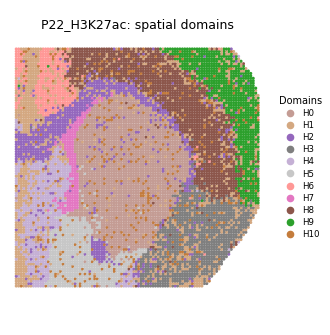

In [12]:
from seareg import plotting
from tutorials.seareg_tutorial_style import tutorial_domain_style
from matplotlib import pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", bbox_inches=None)
figures = {}
plot_labels, domain_palette = tutorial_domain_style(
    domain_result.labels if domain_result is not None else None, 'P22_H3K27ac')
if domain_result is not None:
    figures["spatial_domains"], ax = plotting.spatial_domains(
        domain_result.coordinates, plot_labels, palette=domain_palette,
        title=f"{DATASET}: spatial domains", point_size=5,
    )
    display(figures["spatial_domains"])
    plt.close(figures["spatial_domains"])


## 12. Spot UMAP

Plot the spot UMAP fitted in step 10 using the same spatial-domain names and colors.


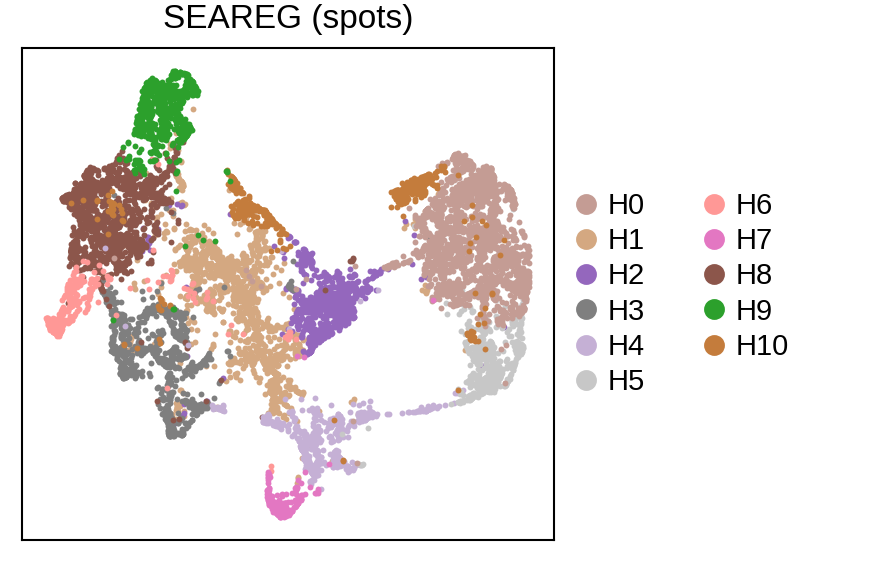

In [13]:
if spot_result is not None:
    figures["spot_umap"], ax = plotting.spot_umap(
        spot_result.table, labels=plot_labels, palette=domain_palette, title="SEAREG (spots)", point_size=2,
    )
    display(figures["spot_umap"], metadata={"image/png": {"width": 950}})
    plt.close(figures["spot_umap"])


## 13. Spot–peak–motif joint UMAP

Plot all learned node types in the shared space: domain-colored circles for spots, gray triangles for peaks and dark squares for motifs when present.


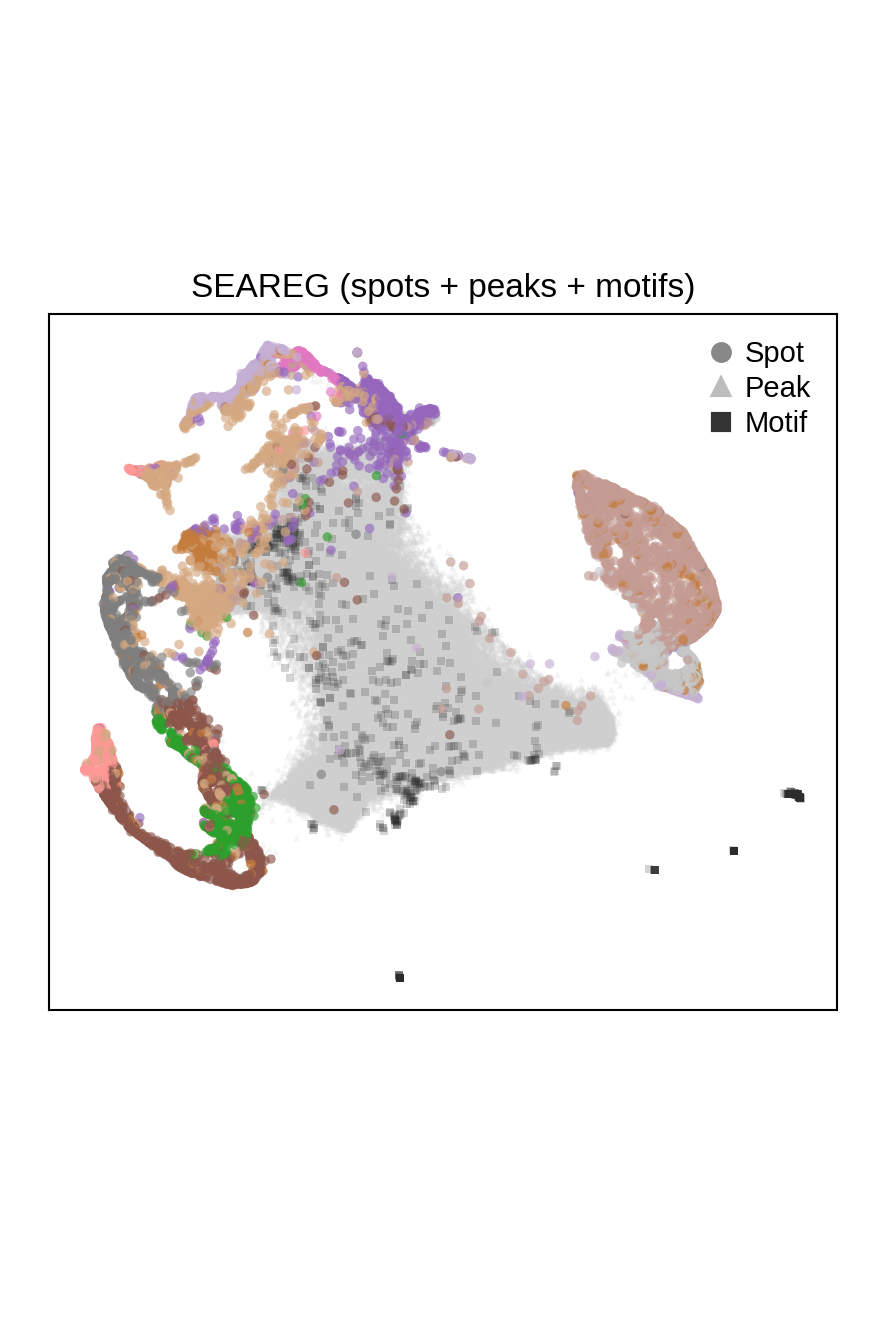

In [14]:
if joint_result is not None:
    figures["joint_umap"], ax = plotting.joint_umap(
        joint_result.table, labels=plot_labels, palette=domain_palette,
        title="SEAREG (spots + peaks + motifs)",
        point_size=5.2, peak_size=2.4, motif_size=4.2,
    )
    display(figures["joint_umap"], metadata={"image/png": {"width": 950}})
    plt.close(figures["joint_umap"])


## 14. Export figures and the execution receipt

Save PNG, editable PDF and SVG figures in `RUN_DIR / "figures"`. The run’s `tutorial_execution.json` records the data, model outputs and analysis configuration.


In [15]:
figure_directory = RUN_DIR / "figures"
exports_started = time.perf_counter()
saved_figures = []
for name, fig in figures.items():
    is_embedding = name in {"spot_umap", "joint_umap"}
    paths = plotting.save_figure(fig, figure_directory / name,
                               dpi=300 if is_embedding else 450,
                               bbox_inches=None if is_embedding else "tight")
    saved_figures.extend({"figure": name, "file": path.name} for path in paths)
    plt.close(fig)
package_root = Path(sr.__file__).parent
source_hashes = {str(path.relative_to(package_root)): hashlib.sha256(path.read_bytes()).hexdigest()
                 for path in sorted(package_root.rglob("*.py"))}
receipt = {
    "dataset_id": DATASET, "package_version": sr.__version__, "fresh_training": RUN_MODE == "train", "run_mode": RUN_MODE,
    "run": display_path(RUN_DIR), "training": display_path(training.path) if training is not None else None,
    "analysis": display_path(result.path), "input_sha256": input_hashes,
    "configuration_profile": display_path(CONFIG_PATH), "configuration_profile_sha256": file_sha256(CONFIG_PATH),
    "analysis_config": asdict(analysis_config), "target_k": TARGET_K,
    "analysis_manifest_sha256": file_sha256(result.path / "analysis_manifest.json"),
    "embedding_directory": display_path(EMBEDDING_DIR),
    "training_config": asdict(training_config) if training is not None else None,
    "motif_annotation": motif_input if RUN_MODE == "train" else None,
    "analysis_embedding_input": embeddings.provenance, "analysis_nodes": analysis_node_counts,
    "source_sha256": source_hashes, "nodes": node_counts, "epochs": training.final_epoch if training is not None else None,
    "optimizer_steps": training_metadata["optimizer_steps"] if training_metadata is not None else None, "stage_seconds": stage_seconds,
    "execution_seconds_before_exports": exports_started - notebook_started,
    "execution": execution, "loss_execution": training_metadata["loss_execution"] if training_metadata is not None else None,
    "torch_memory": training_metadata["torch_memory"] if training_metadata is not None else None,
}
(RUN_DIR / "tutorial_execution.json").write_text(json.dumps(receipt, indent=2) + "\n")
display(pd.DataFrame(saved_figures))
print("Execution record: tutorial_execution.json")


,figure,file
0,spatial_domains,spatial_domains.png
1,spatial_domains,spatial_domains.pdf
2,spatial_domains,spatial_domains.svg
3,spot_umap,spot_umap.png
4,spot_umap,spot_umap.pdf
5,spot_umap,spot_umap.svg
6,joint_umap,joint_umap.png
7,joint_umap,joint_umap.pdf
8,joint_umap,joint_umap.svg


Execution record: tutorial_execution.json
